# KO6 — Combined Scatter: Healthy vs PDAC × Classical vs Basal-like

## Overview
Places every individual (healthy + all PDAC patients) on two axes computed by the two prior KO6 analyses:

- **X — HvP score**: the representative cross-validated/subbagged LDA discriminant score from `KO6_Healthy_PDAC_LDA.ipynb` (Pathogenic Binary representation, representative bootstrap draw selected by F1 closest to mean F1). Out-of-fold — honest.
- **Y — CvB score**: a single, non-bootstrapped "apparent" LDA fit (Binary representation) on the real Classical+Basal patients from `KO6_Classical_Basal_LDA.ipynb`'s cohort, then used to project every individual (including healthy and unknown-subtype PDAC, neither of which the model was trained on). In-sample, and extrapolated for non-CvB-trained groups — **not** generalization evidence.

This notebook reuses `KO6_Healthy_PDAC_LDA.ipynb`'s exported representative-draw scores directly (no recomputation of the bootstrap/CV pipeline) and computes the CvB apparent fit fresh, since neither existing notebook has a single full-data CvB fit nor CvB-pathway features for healthy individuals.

## Data

**Input**
- `results/HvP_V2/LDA_KoCoFX_HvP_V2_representative_scores.parquet` — per-sample HvP
  discriminant scores from the representative bootstrap draw exported by `KO6_3_Healthy_PDAC_LDA.ipynb`.
- `results/HvP_V2/LDA_KoCoFX_HvP_V2_representative_draw.json` — metadata identifying the
  representative draw index (`rep_b_path`) used to select the matching healthy bootstrap partition.
- `merged_tcga_1000G.parquet` — TCGA-PAAD somatic mutations + 1000G germline variants with
  `subtype` labels; used to build CvB feature matrices.
- `healthy_downsampled_bootstrap.parquet` — bootstrap partitions of 1000G variant profiles;
  the representative draw (`rep_b_path`) is used so both axes share the same healthy variant profiles.
- Reactome hierarchy flat files + Hallmark gene sets (GSEApy) — used to resolve the 9 KoCoFX-CB pathway gene sets.

**Processing**
- Load pre-computed HvP scores (X-axis) directly; no re-running of the bootstrap / CV pipeline.
- Build CvB-Binary feature matrices for all 3,369 individuals (142 labelled PDAC + 25 uncertain + 3,202 healthy).
- Fit a single full-data (apparent) CvB LDA on 142 labelled patients; project all individuals onto the CvB axis (Y-axis).

**Output**
- `../Figures/KO6_Scatter_HvP_CvB.{pdf,png,svg}` — 2-D scatter of all individuals in HvP × CvB space.
- `../Figures/KO6_Silhouette_pub.{pdf,png,svg}` — silhouette plot (Healthy / Classical / Basal-like) in Z-scored HvP × CvB space.

## Method

- **X-axis (HvP score)**: the representative-draw out-of-fold LDA discriminant score from
  `KO6_3_Healthy_PDAC_LDA.ipynb` (Pathogenic Binary representation; draw selected by F1
  closest to mean F1). Honest: out-of-fold, cross-validated.
- **Y-axis (CvB score)**: a single full-data (apparent) LDA fit on the 142 labelled TCGA
  patients using the 9 KoCoFX-CB Binary pathway features. Scores for healthy and uncertain
  individuals are extrapolated through a model never trained on their feature region.
  **Not** a generalisation estimate.
- **Healthy CvB features**: derived from the same representative bootstrap draw (`rep_b_path`)
  as the HvP scores, ensuring both axes use a consistent version of each healthy individual's
  variant profile.
- **Silhouette plot**: Euclidean distance in Z-scored (HvP, CvB) space; Uncertain group excluded.
  Computed per-group to quantify cluster compactness.

## Content

| # | Name | Description |
|---|------|-------------|
| 1 | Setup | Imports, paths (`DATA_DIR`, `RESULTS_DIR_HVP`, `RESULTS_DIR_OUT`), constants, colour palette, `build_koco_matrix` helper |
| 2 | Load HvP scores | Read representative-draw HvP scores and draw metadata exported by KO6_3 |
| 3 | CvB cohort identification | Load TCGA metadata; exclude hypermutator; define Classical / Basal-like / Uncertain cohorts; assert cohort alignment with HvP export |
| 4 | Pathway gene sets | Reactome L2–L4 + Hallmark; verify 9 KoCoFX-CB pathway names present in `pw_sets` |
| 5 | CvB-Binary features for the full union | Build Binary matrices for 142 labelled PDAC, 25 uncertain, 3,202 healthy (using `rep_b_path` bootstrap partition) |
| 6 | Single non-bootstrapped CvB "apparent" fit | Fit CvB LDA on 142 patients; project all individuals; print per-pathway positivity rates |
| 7 | Unified per-sample table | Join HvP and CvB scores into a single `df_plot` Polars DataFrame; group-count sanity check |
| 8 | Scatter plot | 2-D scatter (HvP × CvB) with group colours; saved as `KO6_Scatter_HvP_CvB.{pdf,png,svg}` |
| 9 | Closing notes | Caveats: apparent Y-axis, extrapolated healthy/uncertain, axis interpretation |
| 10 | Silhouette plot — publication-ready | Per-group silhouette coefficients in Z-scored space; saved as `KO6_Silhouette_pub.{pdf,png,svg}` |

In [1]:
from collections import defaultdict, deque
import json
import re
import warnings
from pathlib import Path

import gseapy as gp
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler

pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)

DATA_DIR          = Path('C:/Users/daane/Desktop/DATA')
REPO_DATA         = Path('../3_Data')   # merged + healthy bootstrap parquets shipped with the repo
# DATA_DIR          = Path('C:/2604_BRP/Data')
PARQUET           = REPO_DATA / 'merged_tcga_1000G.parquet'
BOOTSTRAP_PARQUET = REPO_DATA / 'healthy_downsampled_bootstrap.parquet'
REACTOME_DIR      = DATA_DIR / 'reactome_hierarchy'
RESULTS_DIR_HVP   = DATA_DIR / 'results' / 'HvP_V2'
RESULTS_DIR_OUT   = DATA_DIR / 'results' / 'KO6_Scatter'
RESULTS_DIR_OUT.mkdir(parents=True, exist_ok=True)

MAX_REACTOME_LEVEL = 3
MIN_REACTOME_LEVEL = 1
SUBTYPE_CLASSICAL  = 'classical'
SUBTYPE_BASAL      = 'basal-like'

KOCOFX_CB_PATHWAYS = [
    'HALLMARK_KRAS Signaling Up',
    'REACTOME_Formation of the cornified envelope',
    'HALLMARK_Fatty Acid Metabolism',
    'REACTOME_Innate Immune System',
    'REACTOME_Generic Transcription Pathway',
    'REACTOME_RNA Polymerase II Transcription',
    'REACTOME_Nervous system development',
    'HALLMARK_Apical Junction',
    'REACTOME_Transport of Mature mRNA derived from an Intron-Containing Transcript',
]

WONG = {
    'orange':    '#E69F00',
    'sky_blue':  '#56B4E9',
    'green':     '#009E73',
    'blue':      '#0072B2',
    'vermilion': '#D55E00',
    'pink':      '#CC79A7',
}
YELLOW_WARM = '#E6C229'   # Classical
RED_DEEP    = '#C72C2C'   # Basal-like
GRAY        = '#999999'  # Uncertain


def build_koco_matrix(sample_ids, sample_gene_sets, pathways, pw_sets):
    # Binary: 1.0 if any mutated gene overlaps pathway gene set, else 0.0
    gene_to_pw = defaultdict(list)
    for j, pw in enumerate(pathways):
        for g in pw_sets[pw]:
            gene_to_pw[g].append(j)
    X = np.zeros((len(sample_ids), len(pathways)), dtype=np.float32)
    for i, sid in enumerate(sample_ids):
        for g in sample_gene_sets.get(sid, set()):
            for j in gene_to_pw.get(g, []):
                X[i, j] = 1.0
    return X


print(f'Results dir (HvP source) : {RESULTS_DIR_HVP}')
print(f'Results dir (this output): {RESULTS_DIR_OUT}')
print(f'Parquet exists            : {PARQUET.exists()}')
print(f'Bootstrap parquet exists  : {BOOTSTRAP_PARQUET.exists()}')

KeyboardInterrupt: 

## 2. Load HvP scores (exported by `KO6_Healthy_PDAC_LDA.ipynb`)

In [ ]:
df_hvp = pl.read_parquet(RESULTS_DIR_HVP / 'LDA_KoCoFX_HvP_V2_representative_scores.parquet')
assert df_hvp.shape[0] == 3369, f'Expected 3369 rows, got {df_hvp.shape[0]}'
assert df_hvp['rep_score_path'].null_count() == 0

healthy_ids  = sorted(df_hvp.filter(pl.col('group') == 'Healthy')['sample_id'].to_list())
pdac_ids_hvp = sorted(df_hvp.filter(pl.col('group') == 'PDAC')['sample_id'].to_list())

hvp_score_by_id = dict(zip(df_hvp['sample_id'].to_list(), df_hvp['rep_score_path'].to_list()))

rep_draw_info = json.loads(
    (RESULTS_DIR_HVP / 'LDA_KoCoFX_HvP_V2_representative_draw.json').read_text(encoding='utf-8')
)
rep_b_path = rep_draw_info['rep_b_path']

print(f'df_hvp shape    : {df_hvp.shape}')
print(f'Healthy         : {len(healthy_ids)}')
print(f'PDAC (from HvP) : {len(pdac_ids_hvp)}')
print(f'Representative draw (Pathogenic Binary, from HvP export): rep_b_path={rep_b_path}')

df_hvp shape    : (3369, 5)
Healthy         : 3202
PDAC (from HvP) : 167
Representative draw (Pathogenic Binary, from HvP export): rep_b_path=31


## 3. CvB cohort identification

In [ ]:
df_meta = (
    pl.read_parquet(PARQUET, columns=['source', 'sample_id', 'subtype'])
    .unique('sample_id')
)

tmb_df = (
    pl.read_parquet(PARQUET, columns=['source', 'sample_id'])
    .filter(pl.col('source') == 'TCGA')
    .group_by('sample_id').agg(pl.len().alias('tmb'))
)
hypermutator_ids = set(
    tmb_df.filter(pl.col('tmb') > 500)['sample_id'].to_list()
)

df_tcga_meta = (
    df_meta
    .filter(
        (pl.col('source') == 'TCGA') &
        ~pl.col('sample_id').is_in(hypermutator_ids)
    )
    .sort('sample_id')
)

df_cvb  = df_tcga_meta.filter(pl.col('subtype').is_in([SUBTYPE_CLASSICAL, SUBTYPE_BASAL]))
cvb_ids = df_cvb['sample_id'].to_list()
y_cvb   = (df_cvb['subtype'] == SUBTYPE_BASAL).cast(pl.Int8).to_numpy()

classical_ids = [cvb_ids[i] for i in range(len(cvb_ids)) if y_cvb[i] == 0]
basal_ids     = [cvb_ids[i] for i in range(len(cvb_ids)) if y_cvb[i] == 1]
n_classical   = len(classical_ids)
n_basal       = len(basal_ids)
n_cvb         = len(cvb_ids)

df_unknown = df_tcga_meta.filter(
    pl.col('subtype').is_null() | ~pl.col('subtype').is_in([SUBTYPE_CLASSICAL, SUBTYPE_BASAL])
)
unknown_ids = df_unknown['sample_id'].to_list()
n_unknown   = len(unknown_ids)

# Sample-id join discipline: pdac_ids_hvp (from the HvP export, globally sorted) and
# classical_ids+basal_ids+unknown_ids (from this cohort cell, grouped by subtype) are the
# SAME 167-id set but in a DIFFERENT order — never zip/concat across the two; always join by id.
assert sorted(pdac_ids_hvp) == sorted(classical_ids + basal_ids + unknown_ids), (
    'PDAC cohort mismatch between HvP export and CvB cohort definition'
)

print(f'Classical  : {n_classical}')
print(f'Basal-like : {n_basal}')
print(f'Unknown    : {n_unknown}')
print(f'CvB total  : {n_cvb}')
print('Cohort alignment check: OK (same 167 PDAC ids, different order — join by sample_id only)')

Classical  : 81
Basal-like : 61
Unknown    : 25
CvB total  : 142
Cohort alignment check: OK (same 167 PDAC ids, different order — join by sample_id only)


## 4. Pathway gene sets (Reactome + Hallmark)

In [ ]:
pw_txt  = (REACTOME_DIR / 'ReactomePathways.txt').read_text(encoding='utf-8')
rel_txt = (REACTOME_DIR / 'ReactomePathwaysRelation.txt').read_text(encoding='utf-8')
gmt_txt = (REACTOME_DIR / 'ReactomePathways.gmt').read_text(encoding='utf-8')

human_id_to_name: dict = {}
for line in pw_txt.strip().splitlines():
    parts = line.split('\t')
    if len(parts) >= 3 and parts[2].strip() == 'Homo sapiens':
        human_id_to_name[parts[0].strip()] = parts[1].strip()
human_ids = set(human_id_to_name)

parent_to_children: dict = defaultdict(set)
child_to_parents:   dict = defaultdict(set)
for line in rel_txt.strip().splitlines():
    parts = line.strip().split('\t')
    if len(parts) < 2:
        continue
    parent, child = parts[0], parts[1]
    if parent in human_ids and child in human_ids:
        parent_to_children[parent].add(child)
        child_to_parents[child].add(parent)

all_in_dag = set(parent_to_children) | set(child_to_parents)
roots      = {pid for pid in all_in_dag if pid not in child_to_parents}
level_of: dict = {}
queue = deque()
for r in roots:
    level_of[r] = 0
    queue.append(r)
while queue:
    node = queue.popleft()
    for child in parent_to_children.get(node, set()):
        if child not in level_of:
            level_of[child] = level_of[node] + 1
            queue.append(child)

gmt_by_id: dict = {}
for line in gmt_txt.strip().splitlines():
    parts = line.split('\t')
    if len(parts) < 3:
        continue
    name  = parts[0]
    url   = parts[1]
    genes = {g.strip() for g in parts[2:] if g.strip()}
    m = re.search(r'R-HSA-\d+', url)
    if not m:
        continue
    rid = m.group(0)
    gmt_by_id[rid] = {'name': name, 'genes': genes}

_raw_hallmark = gp.get_library('MSigDB_Hallmark_2020')
hallmark_sets = {k: set(v) for k, v in _raw_hallmark.items()}

reactome_selected: dict = {}
for rid, info in gmt_by_id.items():
    if MIN_REACTOME_LEVEL <= level_of.get(rid, 99) <= MAX_REACTOME_LEVEL and info['genes']:
        reactome_selected[info['name']] = info['genes']

pw_sets: dict = {}
for name, genes in hallmark_sets.items():
    pw_sets[f'HALLMARK_{name}'] = genes
for name, genes in reactome_selected.items():
    key = f'REACTOME_{name}'
    if key not in pw_sets:
        pw_sets[key] = genes

for pw in KOCOFX_CB_PATHWAYS:
    if pw not in pw_sets:
        raise KeyError(f'Pathway not found in pw_sets: {pw!r}')

print(f'Total pw_sets: {len(pw_sets)}')
print('All 9 KoCoFX-CB pathways found: OK')

Total pw_sets: 1662
All 9 KoCoFX-CB pathways found: OK


## 5. CvB-Binary features for the full union (PDAC + healthy)

In [ ]:
all_pdac_ids = list(set(cvb_ids + unknown_ids))

df_mut_pdac = (
    pl.read_parquet(
        PARQUET,
        columns=['source', 'sample_id', 'gene_symbol', 'gene_name'],
    )
    .filter(
        (pl.col('source') == 'TCGA') & pl.col('sample_id').is_in(all_pdac_ids)
    )
    .with_columns(pl.coalesce(['gene_symbol', 'gene_name']).alias('gene'))
    .drop_nulls('gene')
    .unique(['sample_id', 'gene'])
)

sample_gene_sets_cb: dict = {}   # sid -> set of mutated gene names
for row in df_mut_pdac.group_by('sample_id').agg(pl.col('gene')).iter_rows(named=True):
    sample_gene_sets_cb[row['sample_id']] = set(row['gene'])

# Healthy: reuse the SAME representative bootstrap draw (rep_b_path) selected for the X-axis,
# so both axes are derived from the same version of each healthy individual's resampled
# mutation profile, rather than mixing a bootstrap-drawn X with a raw, un-bootstrapped Y.
df_mut_healthy = (
    pl.scan_parquet(BOOTSTRAP_PARQUET)
    .filter(pl.col('bootstrap_id') == rep_b_path)
    .select(['sample_id', 'gene_name'])
    .unique()
    .collect()
)
for row in df_mut_healthy.group_by('sample_id').agg(pl.col('gene_name')).iter_rows(named=True):
    sample_gene_sets_cb[row['sample_id']] = set(row['gene_name'])

n_pdac_covered    = sum(1 for sid in all_pdac_ids if sid in sample_gene_sets_cb)
n_healthy_covered = sum(1 for sid in healthy_ids if sid in sample_gene_sets_cb)
print(f'PDAC ids with gene-set entries    : {n_pdac_covered} / {len(all_pdac_ids)}')
print(f'Healthy ids with gene-set entries : {n_healthy_covered} / {len(healthy_ids)}  (bootstrap draw {rep_b_path})')

PDAC ids with gene-set entries    : 167 / 167
Healthy ids with gene-set entries : 3202 / 3202  (bootstrap draw 31)


## 6. Single non-bootstrapped CvB "apparent" fit

The original `KO6_Classical_Basal_LDA.ipynb` bootstrap pipeline uses a block-ordered `y_base_cvb = [0]*n_classical + [1]*n_basal` together with a `boot_idx` step that regroups `X_cvb_binary` rows into matching classical-then-basal order before fitting. This fit instead uses the full, non-bootstrapped `X_cvb_binary` (rows in `cvb_ids`'s natural, sorted order — never regrouped), so it must use `y_cvb` (row-aligned to `cvb_ids`) — using `y_base_cvb` here would silently mispair labels and features.

In [ ]:
X_cvb_binary = build_koco_matrix(cvb_ids, sample_gene_sets_cb, KOCOFX_CB_PATHWAYS, pw_sets)

sc_cvb  = StandardScaler().fit(X_cvb_binary)
lda_cvb = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto')
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    lda_cvb.fit(sc_cvb.transform(X_cvb_binary), y_cvb)   # y_cvb, NOT y_base_cvb — see note above

cvb_score_classical_basal = lda_cvb.decision_function(sc_cvb.transform(X_cvb_binary))

X_unknown_binary  = build_koco_matrix(unknown_ids, sample_gene_sets_cb, KOCOFX_CB_PATHWAYS, pw_sets)
cvb_score_unknown = lda_cvb.decision_function(sc_cvb.transform(X_unknown_binary))

X_healthy_binary  = build_koco_matrix(healthy_ids, sample_gene_sets_cb, KOCOFX_CB_PATHWAYS, pw_sets)
cvb_score_healthy = lda_cvb.decision_function(sc_cvb.transform(X_healthy_binary))

print('Per-pathway positivity rate (fraction of individuals with >=1 mutated gene in pathway):')
print(f'{"Pathway":<55}  {"PDAC (CvB)":>11}  {"Healthy":>9}')
for j, pw in enumerate(KOCOFX_CB_PATHWAYS):
    print(f'{pw:<55}  {100*(X_cvb_binary[:, j] > 0).mean():>10.1f}%  {100*(X_healthy_binary[:, j] > 0).mean():>8.1f}%')
print()
print('NOTE: healthy individuals carry far more germline mutated genes than PDAC patients carry')
print('somatic ones, so a near-saturated (all-ones) Binary feature vector for healthy individuals')
print('is EXPECTED, not a bug -- see Section 9 caveat.')

Per-pathway positivity rate (fraction of individuals with >=1 mutated gene in pathway):
Pathway                                                   PDAC (CvB)    Healthy
HALLMARK_KRAS Signaling Up                                     27.5%      19.8%
REACTOME_Formation of the cornified envelope                   15.5%      29.2%
HALLMARK_Fatty Acid Metabolism                                 12.7%      12.6%
REACTOME_Innate Immune System                                  86.6%      72.9%
REACTOME_Generic Transcription Pathway                         90.8%      60.4%
REACTOME_RNA Polymerase II Transcription                       90.8%      61.0%
REACTOME_Nervous system development                            85.2%      39.0%
HALLMARK_Apical Junction                                       32.4%      20.8%
REACTOME_Transport of Mature mRNA derived from an Intron-Containing Transcript         7.7%       5.2%

NOTE: healthy individuals carry far more germline mutated genes than PDAC patients carry

## 7. Unified per-sample table

In [ ]:
cvb_score_by_id = {}
cvb_score_by_id.update(dict(zip(cvb_ids, cvb_score_classical_basal)))
cvb_score_by_id.update(dict(zip(unknown_ids, cvb_score_unknown)))
cvb_score_by_id.update(dict(zip(healthy_ids, cvb_score_healthy)))

classical_set = set(classical_ids)
basal_set     = set(basal_ids)
unknown_set   = set(unknown_ids)
healthy_set   = set(healthy_ids)


def classify(sid):
    if sid in healthy_set:
        return 'Healthy'
    if sid in classical_set:
        return 'Classical'
    if sid in basal_set:
        return 'Basal'
    if sid in unknown_set:
        return 'Uncertain'
    raise ValueError(f'Unrecognized sample_id: {sid}')


rows = [
    {
        'sample_id': sid,
        'group': classify(sid),
        'hvp_score': hvp_score,
        'cvb_score': cvb_score_by_id[sid],
    }
    for sid, hvp_score in hvp_score_by_id.items()
]
df_plot = pl.DataFrame(rows)

assert df_plot.shape[0] == 3369
assert df_plot['cvb_score'].null_count() == 0
print(df_plot.group_by('group').agg(pl.len()).sort('group'))

shape: (4, 2)
┌───────────┬──────┐
│ group     ┆ len  │
│ ---       ┆ ---  │
│ str       ┆ u32  │
╞═══════════╪══════╡
│ Basal     ┆ 61   │
│ Classical ┆ 81   │
│ Healthy   ┆ 3202 │
│ Uncertain ┆ 25   │
└───────────┴──────┘


## 8. Scatter plot

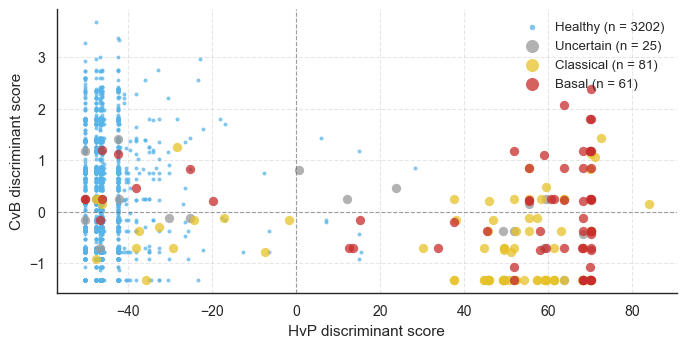

Saved to C:\Users\daane\Desktop\GitHub Repos\Bachelor_Research_Project\Figures


In [ ]:
import seaborn as sns

FIG_DIR = Path('../Figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

group_colors = {
    'Healthy':   WONG['sky_blue'],
    'Uncertain': GRAY,
    'Classical': YELLOW_WARM,
    'Basal':     RED_DEEP,
}
group_sizes = {
    'Healthy':   8,
    'Uncertain': 45,
    'Classical': 45,
    'Basal':     45,
}
group_order = ['Healthy', 'Uncertain', 'Classical', 'Basal']

with sns.axes_style('white'), sns.plotting_context('paper', font_scale=1.15):

    fig, ax = plt.subplots(figsize=(183/25.4, 3.5))

    for group in group_order:
        sub = df_plot.filter(pl.col('group') == group)
        ax.scatter(
            sub['hvp_score'], sub['cvb_score'],
            s=group_sizes[group],
            c=group_colors[group],
            alpha=0.75,
            linewidths=0,
            label=f'{group} (n = {sub.shape[0]})',
        )

    ax.axvline(0, color='#444444', lw=0.8, ls='--', alpha=0.45)
    ax.axhline(0, color='#444444', lw=0.8, ls='--', alpha=0.45)
    ax.xaxis.grid(True, linestyle='--', alpha=0.35, color='#bbbbbb')
    ax.yaxis.grid(True, linestyle='--', alpha=0.35, color='#bbbbbb')
    ax.set_axisbelow(True)

    ax.set_xlabel('HvP discriminant score')
    ax.set_ylabel('CvB discriminant score')
    ax.legend(fontsize=9.5, frameon=False, markerscale=1.4, loc='upper right')

    sns.despine(ax=ax)

    fig.subplots_adjust(left=0.11, right=0.97, top=0.97, bottom=0.16)
    fig.savefig(FIG_DIR / 'KO6_Scatter_HvP_CvB.pdf', dpi=300, bbox_inches='tight')
    fig.savefig(FIG_DIR / 'KO6_Scatter_HvP_CvB.png', dpi=300, bbox_inches='tight')
    with mpl.rc_context({'svg.fonttype': 'none'}):
        fig.savefig(FIG_DIR / 'KO6_Scatter_HvP_CvB.svg', bbox_inches='tight')
    plt.show()

print(f'Saved to {FIG_DIR.resolve()}')

## 9. Closing notes

Two caveats apply to the Y-axis (CvB score), not one — both are stated only in the plot caption now; dot style (size/fill) no longer encodes them:

1. The whole axis is an apparent, in-sample fit — even for Classical and Basal patients, who the model was at least trained on. The visual spread between them has not been validated out-of-fold and is not evidence of generalizable separability.
2. Healthy and Uncertain (no-subtype-label) PDAC individuals are additionally extrapolated through a model that never saw their feature region. Their Y-position carries no trained meaning at all. Healthy individuals' mutation profiles for both axes come from the same representative bootstrap draw (`rep_b_path`) used for the HvP score, so the X and Y axes are at least built from a consistent version of each healthy individual's data.

The X-axis (HvP score) is the one honest axis here: out-of-fold, cross-validated, from a representative bootstrap draw selected by F1 closest to the mean F1 across 1,000 draws.

As with all LDA score visualizations in this project, this plot is descriptive only — it does not by itself demonstrate separation between any of the groups shown.

## 10. Silhouette plot — publication-ready

Healthy vs PDAC subtypes in HvP × CvB space. Uncertain excluded. Z-scored axes, Euclidean distance.

In [ ]:
from sklearn.metrics import silhouette_samples

df_sil   = df_plot.filter(pl.col('group') != 'Uncertain')
X_sil    = df_sil[['hvp_score', 'cvb_score']].to_numpy().astype(float)
X_sil_z  = StandardScaler().fit_transform(X_sil)
labels   = df_sil['group'].to_numpy()
sil_vals = silhouette_samples(X_sil_z, labels)

sil_by_group = {}
for grp in ['Healthy', 'Classical', 'Basal']:
    mask = labels == grp
    sil_by_group[grp] = np.sort(sil_vals[mask])  # ascending: smallest at bottom, largest at top

for grp, vals in sil_by_group.items():
    print(f'{grp:12s}: n={len(vals):5d},  mean={vals.mean():.4f}')

Healthy     : n= 3202,  mean=0.7477
Classical   : n=   81,  mean=0.0081
Basal       : n=   61,  mean=-0.1167


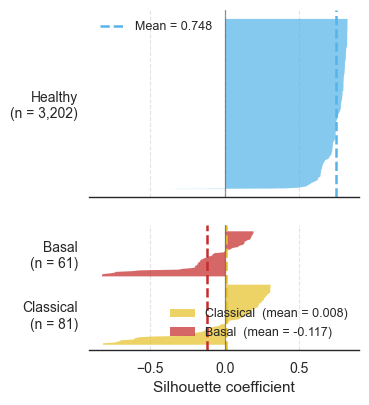

Saved to C:\Users\daane\Desktop\GitHub Repos\Bachelor_Research_Project\Figures


In [ ]:
import seaborn as sns

with sns.axes_style('white'), sns.plotting_context('paper', font_scale=1.15):

    fig, (ax_top, ax_bot) = plt.subplots(
        2, 1,
        figsize=(91.5/25.4, 4.0),
        height_ratios=[3, 2],
        sharex=True,
    )

    # — Top: Healthy —
    sil_h  = sil_by_group['Healthy']
    n_h    = len(sil_h)
    mean_h = sil_h.mean()

    ax_top.fill_betweenx(np.arange(n_h), 0, sil_h,
                         color=WONG['sky_blue'], alpha=0.72, linewidth=0)
    ax_top.axvline(mean_h, color=WONG['sky_blue'], lw=1.8, ls='--',
                   label=f'Mean = {mean_h:.3f}')
    ax_top.axvline(0, color='#444444', lw=0.9, alpha=0.55)
    ax_top.set_yticks([n_h / 2])
    ax_top.set_yticklabels([f'Healthy\n(n = {n_h:,})'], fontsize=10)
    ax_top.legend(fontsize=9, frameon=False, loc='upper left')
    ax_top.xaxis.grid(True, linestyle='--', alpha=0.4, color='#bbbbbb')
    ax_top.set_axisbelow(True)
    sns.despine(ax=ax_top, left=True)
    ax_top.tick_params(left=False)

    # — Bottom: Classical + Basal-like —
    y_lower = 10
    tick_pos, tick_lab = [], []
    for group, color in [('Classical', YELLOW_WARM), ('Basal', RED_DEEP)]:
        sil_g   = sil_by_group[group]
        n_g     = len(sil_g)
        mean_g  = sil_g.mean()
        y_upper = y_lower + n_g
        ax_bot.fill_betweenx(np.arange(y_lower, y_upper), 0, sil_g,
                             color=color, alpha=0.72, linewidth=0,
                             label=f'{group}  (mean = {mean_g:.3f})')
        ax_bot.axvline(mean_g, color=color, lw=1.8, ls='--')
        tick_pos.append((y_lower + y_upper) / 2)
        tick_lab.append(f'{group}\n(n = {n_g})')
        y_lower = y_upper + 10

    ax_bot.axvline(0, color='#444444', lw=0.9, alpha=0.55)
    ax_bot.set_yticks(tick_pos)
    ax_bot.set_yticklabels(tick_lab, fontsize=10)
    ax_bot.set_xlabel('Silhouette coefficient')
    ax_bot.legend(fontsize=9, frameon=False, loc='lower right', ncol=1)
    ax_bot.xaxis.grid(True, linestyle='--', alpha=0.4, color='#bbbbbb')
    ax_bot.set_axisbelow(True)
    sns.despine(ax=ax_bot, left=True)
    ax_bot.tick_params(left=False)

    fig.subplots_adjust(left=0.22, right=0.97, top=0.97, bottom=0.12, hspace=0.18)
    fig.savefig(FIG_DIR / 'KO6_Silhouette_pub.pdf', dpi=300, bbox_inches='tight')
    fig.savefig(FIG_DIR / 'KO6_Silhouette_pub.png', dpi=300, bbox_inches='tight')
    with mpl.rc_context({'svg.fonttype': 'none'}):
        fig.savefig(FIG_DIR / 'KO6_Silhouette_pub.svg', bbox_inches='tight')
    plt.show()

print(f'Saved to {FIG_DIR.resolve()}')